# 07. Correlation, CAPM

In this section, i intend to move on from "What happened?" (previous section) to understanding the relationships between sectors and estimating an asset's expected return based on how sensitive each stock is to the market.

7.1 - Which sectors move together?   
      (Correlation of sector returns)  
7.2 - How sensitive is each stock to the market?  
      (Beta from a simplified CAPM regression)  
7.3 - Do sectors really differ in market sensitivity and in return?  
      (Hypothesis testing)  

All will be built on returns and not prices. Prices usually trend upward, so two unrelated stocks can look correlated just because both rose over time. Returns remove that trend and compare the day-to-day moves.

Notes:
- CAPM in this project is used without excess returns (return - risk-free rate) because the risk-free rate is assumed to be 0 (simplification purposes and to mach the Sharpe-style ration in section 5). So this is a simplified CAPM market model (stock return = alpha + beta.market return + error), only used to measure each stock's sensitivity to the market (beta) and not to estimate its expected returns.
- Only 7.1 will use the full history because it doesn't need the index data, whilst 7.2 and 7.3 only use the window where SP500 index data exists (2014-12-23 to 2024-12-20) because beta needs the market return on the same day.

#### Load data and libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


features_csv=Path(r"filepath\csv_features")
clean_csv=Path(r"filepath\csv_clean")
stats_csv=Path(r"filepath\csv_stats")

stocks=pd.read_csv(features_csv / "stock_features.csv", usecols=["date","symbol","simple_return"], parse_dates=["date"])
index=pd.read_csv(features_csv / "index_features.csv", usecols=["date","simple_return"], parse_dates=["date"])
companies=pd.read_csv(clean_csv / "companies_clean.csv", usecols=["symbol", "sector"])
sector_daily = pd.read_csv(stats_csv / "sector_daily_returns.csv", parse_dates=["date"])



#### 7.1 Sector correlation

Let's measure the correlation of the returns between sectors.

For this, I will use the sector_daily_returns dataframe which presents one return per sector per day. I will compare each pair of sector only on the days they share.

I will use Pearson's becuase i'm interested in the linear relationship of sector pairs (strength and direction). Furthermore, sector simple returns are quantitative and continuous variables, making Pearson’s correlation an appropriate measure for this analysis.

Here, unlike the SQL track, I'm adding the Spearman's correlation just as a check, because this method is more robust to outliers/extremes since it converts each day with its rank (best day=1, second best=2, etc.) and asks whether the two series rise and fall in the same order.

Each sector is already an average of many stocks, which smooths extremes, so it is expected both methods to not differ that much. 

In [2]:
sector_daily

,date,sector,sector_return
0,2010-01-05,Basic Materials,0.000823
1,2010-01-06,Basic Materials,0.017045
2,2010-01-07,Basic Materials,-0.003449
3,2010-01-08,Basic Materials,0.006786
4,2010-01-11,Basic Materials,-0.003168
...,...,...,...
41432,2024-12-16,Utilities,-0.006881
41433,2024-12-17,Utilities,-0.004604
41434,2024-12-18,Utilities,-0.023679
41435,2024-12-19,Utilities,0.007163


Pearson's:

In [ ]:
#Pearson needs pairs of values in order to run.
#I need to pair my data by date. I only want to pair returns of the same date.
#To do that, i can pivot my data using date as index. So the index will be date and every 
# sector will have its own column.

#Pivoting:
sector_daily_pivot=sector_daily.pivot(index="date",columns="sector",values="sector_return")


#Confirming my data:
#see how many rows and columns:
sector_daily_pivot.shape
#result: (3767, 11) - confirms that i have all daily returns 3767 and all sectors 11

#see if my pivot table has produced any nulls:
sector_daily_pivot.isna().sum()
#result: 0 for all sectors. So every date has a sector return.

#getting the correlation:
pearson_sector_corr=sector_daily_pivot.corr()
#corr(method="pearson") is the default
pearson_sector_corr.round(2)


sector,Basic Materials,Communication Services,Consumer Cyclical,Consumer Defensive,Energy,Financial Services,Healthcare,Industrials,Real Estate,Technology,Utilities
sector,,,,,,,,,,,
Basic Materials,1.00,0.76,0.83,0.65,0.75,0.84,0.74,0.89,0.70,0.79,0.54
Communication Services,0.76,1.00,0.85,0.67,0.60,0.80,0.78,0.83,0.70,0.84,0.53
Consumer Cyclical,0.83,0.85,1.00,0.68,0.66,0.85,0.78,0.91,0.77,0.86,0.55
Consumer Defensive,0.65,0.67,0.68,1.00,0.49,0.70,0.73,0.71,0.70,0.63,0.71
Energy,0.75,0.60,0.66,0.49,1.00,0.70,0.55,0.69,0.56,0.60,0.44
Financial Services,0.84,0.80,0.85,0.70,0.70,1.00,0.78,0.90,0.76,0.80,0.59
Healthcare,0.74,0.78,0.78,0.73,0.55,0.78,1.00,0.81,0.71,0.81,0.59
Industrials,0.89,0.83,0.91,0.71,0.69,0.90,0.81,1.00,0.76,0.86,0.59
Real Estate,0.70,0.70,0.77,0.70,0.56,0.76,0.71,0.76,1.00,0.69,0.74


Plotting the heatmap:

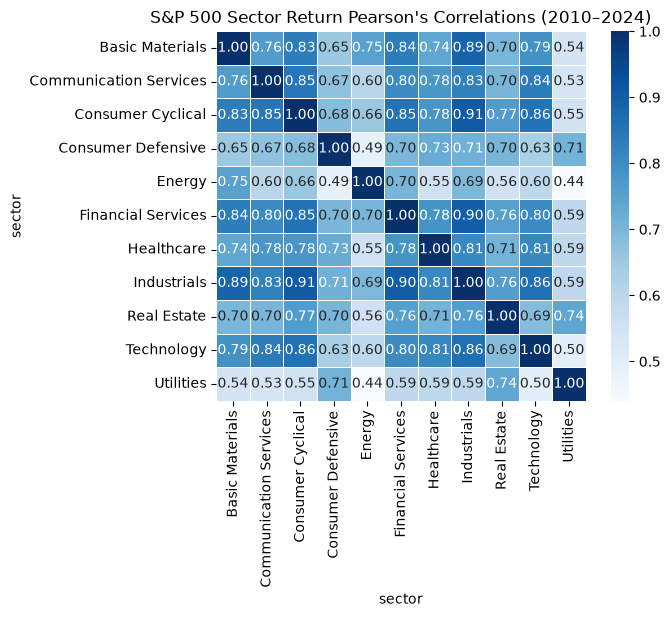

In [ ]:
import seaborn as sns

sns.heatmap(pearson_sector_corr, annot=True, fmt=".2f", cmap="Blues", vmin=pearson_sector_corr.min().min(), vmax=1,  square=True, linewidths=0.5)

plt.title("S&P 500 Sector Return Pearson's Correlations (2010–2024)")
plt.show()

In [ ]:

#for max we first need to remove the diagonal (self correlations):
# 1st - Convert the correlation matrix into a list using stack
pairs = (
    pearson_sector_corr
    .rename_axis(index="sector_1", columns="sector_2")  # both axes are named "sector", which clashes on stack
    .stack()
    .reset_index(name="corr")
)

# 2nd - Exclude the diagonal and duplicate pairs
pairs = pairs[pairs["sector_1"] < pairs["sector_2"]]

# 3rd - Sort by highest correlation or lowest and present top 5 or top 10 etc:
pairs.sort_values("corr", ascending=True).head(10)

# Top 10 corr pairs:

# 	sector_1	sector_2	corr
# 29	Consumer Cyclical	Industrials	0.906160
# 62	Financial Services	Industrials	0.900783
# 7	Basic Materials	Industrials	0.886685
# 86	Industrials	Technology	0.862196
# 31	Consumer Cyclical	Technology	0.856547
# 27	Consumer Cyclical	Financial Services	0.854933
# 13	Communication Services	Consumer Cyclical	0.848662
# 20	Communication Services	Technology	0.836822
# 5	Basic Materials	Financial Services	0.835809
# 2	Basic Materials	Consumer Cyclical	0.834660

# Bot 10 corr pairs:

# 	sector_1	sector_2	corr
# 54	Energy	Utilities	0.440225
# 37	Consumer Defensive	Energy	0.489974
# 109	Technology	Utilities	0.498514
# 21	Communication Services	Utilities	0.534387
# 10	Basic Materials	Utilities	0.540269
# 32	Consumer Cyclical	Utilities	0.547688
# 50	Energy	Healthcare	0.554463
# 52	Energy	Real Estate	0.555923
# 65	Financial Services	Utilities	0.591239
# 87	Industrials	Utilities	0.592606


,sector_1,sector_2,corr
54,Energy,Utilities,0.440225
37,Consumer Defensive,Energy,0.489974
109,Technology,Utilities,0.498514
21,Communication Services,Utilities,0.534387
10,Basic Materials,Utilities,0.540269
32,Consumer Cyclical,Utilities,0.547688
50,Energy,Healthcare,0.554463
52,Energy,Real Estate,0.555923
65,Financial Services,Utilities,0.591239
87,Industrials,Utilities,0.592606


Least correlated pairs:
    Energy	Utilities	0.440225
    Consumer Defensive	Energy	0.489974
    Technology	Utilities	0.498514

Most correlated pairs:
    Consumer Cyclical	Industrials	0.906160
    Financial Services	Industrials	0.900783
    Basic Materials	Industrials	0.886685

Most sector-pair correlations are above 0.5, indicating substantial positive movement across sectors.

Spearman's:

In [6]:
spearman_corr=sector_daily_pivot.corr(method="spearman")
spearman_corr

sector,Basic Materials,Communication Services,Consumer Cyclical,Consumer Defensive,Energy,Financial Services,Healthcare,Industrials,Real Estate,Technology,Utilities
sector,,,,,,,,,,,
Basic Materials,1.000000,0.680996,0.767431,0.557125,0.695416,0.754800,0.648467,0.835255,0.567878,0.712608,0.398193
Communication Services,0.680996,1.000000,0.792708,0.573261,0.533065,0.719086,0.687951,0.746340,0.599114,0.765346,0.407061
Consumer Cyclical,0.767431,0.792708,1.000000,0.609225,0.572039,0.784842,0.707723,0.861524,0.640384,0.799552,0.398439
Consumer Defensive,0.557125,0.573261,0.609225,1.000000,0.411707,0.596377,0.627715,0.612906,0.629049,0.515542,0.617806
Energy,0.695416,0.533065,0.572039,0.411707,1.000000,0.619104,0.473463,0.631898,0.424222,0.523845,0.337482
Financial Services,0.754800,0.719086,0.784842,0.596377,0.619104,1.000000,0.689864,0.843743,0.613083,0.726771,0.436521
Healthcare,0.648467,0.687951,0.707723,0.627715,0.473463,0.689864,1.000000,0.729384,0.605169,0.736208,0.464151
Industrials,0.835255,0.746340,0.861524,0.612906,0.631898,0.843743,0.729384,1.000000,0.638064,0.807001,0.450804
Real Estate,0.567878,0.599114,0.640384,0.629049,0.424222,0.613083,0.605169,0.638064,1.000000,0.572546,0.635894


In [ ]:
(spearman_corr - pearson_sector_corr).abs().max().max()

#result: 0.15471750364923748

0.15471750364923748

In [8]:
#get the table of the differences:
(spearman_corr - pearson_sector_corr).abs()

sector,Basic Materials,Communication Services,Consumer Cyclical,Consumer Defensive,Energy,Financial Services,Healthcare,Industrials,Real Estate,Technology,Utilities
sector,,,,,,,,,,,
Basic Materials,0.000000,0.083237,0.067230,0.096394,0.057043,0.081010,0.091344,0.051430,0.130425,0.075792,0.142075
Communication Services,0.083237,0.000000,0.055954,0.096690,0.071671,0.085363,0.089473,0.080841,0.103231,0.071476,0.127326
Consumer Cyclical,0.067230,0.055954,0.000000,0.073096,0.084970,0.070091,0.073179,0.044636,0.125534,0.056995,0.149249
Consumer Defensive,0.096394,0.096690,0.073096,0.000000,0.078267,0.100234,0.097872,0.099740,0.071861,0.115247,0.089291
Energy,0.057043,0.071671,0.084970,0.078267,0.000000,0.081507,0.081000,0.062984,0.131702,0.073279,0.102743
Financial Services,0.081010,0.085363,0.070091,0.100234,0.081507,0.000000,0.094400,0.057040,0.142004,0.078101,0.154718
Healthcare,0.091344,0.089473,0.073179,0.097872,0.081000,0.094400,0.000000,0.081422,0.103732,0.076496,0.129403
Industrials,0.051430,0.080841,0.044636,0.099740,0.062984,0.057040,0.081422,0.000000,0.121952,0.055196,0.141802
Real Estate,0.130425,0.103231,0.125534,0.071861,0.131702,0.142004,0.103732,0.121952,0.000000,0.112524,0.104628


In [ ]:
pd.DataFrame({
    "paired_sector_row": (spearman_corr - pearson_sector_corr).abs().idxmax(),
    "max_difference": (spearman_corr - pearson_sector_corr).abs().max(),
    "avg_difference": (spearman_corr - pearson_sector_corr).abs().mean(),
    "median_difference": (spearman_corr - pearson_sector_corr).abs().median()
}).rename_axis("paired_sector_col") 

,paired_sector_row,max_difference,avg_difference,median_difference
paired_sector_col,,,,
Basic Materials,Utilities,0.142075,0.079635,0.081010
Communication Services,Utilities,0.127326,0.078660,0.083237
Consumer Cyclical,Utilities,0.149249,0.072812,0.070091
Consumer Defensive,Technology,0.115247,0.083518,0.096394
Energy,Real Estate,0.131702,0.075015,0.078267
Financial Services,Utilities,0.154718,0.085861,0.081507
Healthcare,Utilities,0.129403,0.083484,0.089473
Industrials,Utilities,0.141802,0.072458,0.062984
Real Estate,Financial Services,0.142004,0.104327,0.112524


Removing the diagonal values:

In [ ]:
#The diagonal values should be removed because they contain artificial zeros (difference
# between self pairs) so those zeros are impacting our metrics.

no_diag=((spearman_corr - pearson_sector_corr).abs()).mask(np.eye(len((spearman_corr - pearson_sector_corr)), dtype="bool"))

no_diag

sector,Basic Materials,Communication Services,Consumer Cyclical,Consumer Defensive,Energy,Financial Services,Healthcare,Industrials,Real Estate,Technology,Utilities
sector,,,,,,,,,,,
Basic Materials,NaN,0.083237,0.067230,0.096394,0.057043,0.081010,0.091344,0.051430,0.130425,0.075792,0.142075
Communication Services,0.083237,NaN,0.055954,0.096690,0.071671,0.085363,0.089473,0.080841,0.103231,0.071476,0.127326
Consumer Cyclical,0.067230,0.055954,NaN,0.073096,0.084970,0.070091,0.073179,0.044636,0.125534,0.056995,0.149249
Consumer Defensive,0.096394,0.096690,0.073096,NaN,0.078267,0.100234,0.097872,0.099740,0.071861,0.115247,0.089291
Energy,0.057043,0.071671,0.084970,0.078267,NaN,0.081507,0.081000,0.062984,0.131702,0.073279,0.102743
Financial Services,0.081010,0.085363,0.070091,0.100234,0.081507,NaN,0.094400,0.057040,0.142004,0.078101,0.154718
Healthcare,0.091344,0.089473,0.073179,0.097872,0.081000,0.094400,NaN,0.081422,0.103732,0.076496,0.129403
Industrials,0.051430,0.080841,0.044636,0.099740,0.062984,0.057040,0.081422,NaN,0.121952,0.055196,0.141802
Real Estate,0.130425,0.103231,0.125534,0.071861,0.131702,0.142004,0.103732,0.121952,NaN,0.112524,0.104628


In [11]:
pd.DataFrame({
    "sector_row":no_diag.idxmax(),
    "max_difference": no_diag.max(),
    "avg_difference": no_diag.mean(),
    "median_difference": no_diag.median()
}).rename_axis("paired_sector_col")


,sector_row,max_difference,avg_difference,median_difference
paired_sector_col,,,,
Basic Materials,Utilities,0.142075,0.087598,0.082124
Communication Services,Utilities,0.127326,0.086526,0.084300
Consumer Cyclical,Utilities,0.149249,0.080093,0.071594
Consumer Defensive,Technology,0.115247,0.091869,0.096542
Energy,Real Estate,0.131702,0.082517,0.079634
Financial Services,Utilities,0.154718,0.094447,0.083435
Healthcare,Utilities,0.129403,0.091832,0.090409
Industrials,Utilities,0.141802,0.079704,0.071912
Real Estate,Financial Services,0.142004,0.114759,0.117238


The results are quite different. The rank-based check (Spearman) does not give the same picture. The average pairwise correlation is 0.71 with Pearson and 0.62 with Spearman.  

Check if the difference between pearson and spearman corr is explained by March 2020:  

March 2020 was seen to be an outlier, which pearson's is sensitive to, so let's get the pearson's correlation excluding that particular month of that year.

In [ ]:
#First i will remove the self correlations (diag row) of each corr:
no_diag_pearson_corr=pearson_sector_corr.mask(np.eye(len(pearson_sector_corr),dtype="bool"))
no_diag_spearman_corr=spearman_corr.mask(np.eye(len(spearman_corr),dtype="bool"))

#Excluding march 2020 from our dataframe a calc pearson's corr:
sector_daily_pivot_nomarch=sector_daily_pivot[~((sector_daily_pivot.index.year==2020) & (sector_daily_pivot.index.month==3))]
pearson_corr_nomarch=sector_daily_pivot_nomarch.corr()

#Removing the diagonal from the pearson_corr_nomarch
no_diag_pearson_corr_nomarch=pearson_corr_nomarch.mask(np.eye(len(pearson_corr_nomarch),dtype="bool"))


#Get the mean of pearson_corr with march, without march and spearman:
print("mean pearson's corr with march:", no_diag_pearson_corr.mean().mean())
print("mean pearson's corr without march:", no_diag_pearson_corr_nomarch.mean().mean())
print("mean spearman's corr:", no_diag_spearman_corr.mean().mean())
print("max Pearson's corr with march:", no_diag_pearson_corr.max().max())
print("max Pearson's corr without march:", no_diag_pearson_corr_nomarch.max().max())
print("max Spearman's corr:", no_diag_spearman_corr.max().max())
print("median Pearson's corr with march:", no_diag_pearson_corr.median().median())
print("median Pearson's corr without march:", no_diag_pearson_corr_nomarch.median().median())
print("median Spearman's corr:", no_diag_spearman_corr.median().median())


mean pearson's corr with march: 0.7138101733314995
mean pearson's corr without march: 0.6823418886789357
mean spearman's corr: 0.6206888551898171
max Pearson's corr with march: 0.9061602206190654
max Pearson's corr without march: 0.8996306094589864
max Spearman's corr: 0.861524157058602
median Pearson's corr with march: 0.7586174376712431
median Pearson's corr without march: 0.734484066770521
median Spearman's corr: 0.6844730414871925


Pearson averages 0.71 across sector pairs, against 0.62 for Spearman. Excluding March 2020 only lowers Pearson to 0.68, explaining just 1/3 of the difference between Pearson's and Spearman's first results, so the gap is not driven solely by one event. 

Under both measures, sectors co-move substantially (high averages), so diversification across sectors is limited.

In [13]:
#Pearson corr mean, excluding diag:
(no_diag_pearson_corr).mean().mean()
#0.713

0.7138101733314995

In [14]:
#Pearson corr how pairs above 0.5, excluding diag:
(no_diag_pearson_corr).sum().sum()
#104

# pearson_sector_corr.size -> 121

78.51911906646495

#### 7.2 Market exposure: beta per stock

For each stock i fit one regression over all days where both the stock and the index have a return. I'm checking how the market influences the stock's movement, so that is why i'm pairing equal dates.

Stock Return = Alpha + Beta x Market Return + Error
(simplified version without the Risk Free Rate)

where,
Beta: is the slope, if the market moves 1%, the stock tend to move beta %.
for a simple linear regression,   
beta=  
sum((xt-xmarketmean)(yt-ystockmean))  
/  
(sum(xt-xmarketmean)^2)  

Alpha: is the intercept, the avg daily return not explained by the market.  
For a simple linear regression,  
alpha=ystockmean - beta.xmarketmean  

Error: is the difference between the actual value and the expected value.

After fitting the model, I will then get the R Squared, which measures how well the regression explains historical returns.

Other important terms:

Least squares: i have a scatter plot with one dot per day and each dot represents the market return (x axis) and the stock return (y axis). The regression is the best straight line through all those points. The best line is determined by having the lowest least squares value which are the squared sum of the vertical distances between the point and the regression line (this distance is called residuals)

A stock return and an index (market) return can only be paired when they are from the same day, so the two tables need to be joined on date (inner join for only matching days), so that automatically restricts every regression to the index window.



creating the two tables (stock and market):

In [15]:
market_ret=index.dropna(subset=["simple_return"]).rename(columns={"simple_return":"market_return"})
stock_ret=stocks.dropna(subset=["simple_return"]).rename(columns={"simple_return":"stock_return"})

Merge the two tables (market_ret and stock_ret on date) and also the companies (on symbol) table to get the sector:

In [16]:
merged=(
    stock_ret
    .merge(market_ret,how="inner",on="date")
    .merge(companies, how="inner", on="symbol")
)

print(merged)
print("merged stats:",
      "\n n_rows:", len(merged),
      "\n n_stocks:", merged["symbol"].nunique(),
      "\n n_sectors:", merged["sector"].nunique(),
      "\n start_date:", merged["date"].min().date(),
      #converts timestamp to just date. can't use astype() on scalars.
      "\n end_date:", merged["date"].max().date(),
      "\n n_stocks in stock file but not in the merge:", stocks["symbol"].nunique()-merged["symbol"].nunique(),
      "\n n_stocks:", merged["symbol"].nunique()
      )

              date symbol  stock_return  market_return       sector
0       2014-12-23      A     -0.012178       0.001746   Healthcare
1       2014-12-24      A     -0.005801      -0.000139   Healthcare
2       2014-12-26      A      0.006078       0.003310   Healthcare
3       2014-12-29      A     -0.001209       0.000862   Healthcare
4       2014-12-30      A      0.000968      -0.004889   Healthcare
...            ...    ...           ...            ...          ...
1226812 2024-12-16   AMTM      0.031670       0.003799  Industrials
1226813 2024-12-17   AMTM     -0.095458      -0.003864  Industrials
1226814 2024-12-18   AMTM     -0.054858      -0.029493  Industrials
1226815 2024-12-19   AMTM     -0.068864      -0.000865  Industrials
1226816 2024-12-20   AMTM      0.012678       0.010869  Industrials

[1226817 rows x 5 columns]
merged stats: 
 n_rows: 1226817 
 n_stocks: 502 
 n_sectors: 11 
 start_date: 2014-12-23 
 end_date: 2024-12-20 
 n_stocks in stock file but not in the merg

Check date alignment (every stock should have an index return on the same day)

In [17]:
in_window=stock_ret[(stock_ret["date"] >= market_ret["date"].min()) & (stock_ret["date"] <= market_ret["date"].max())]
unmatched=in_window[~in_window["date"].isin(market_ret["date"])]
unmatched
#no results

,date,symbol,stock_return


Stock CAPM model:

In [ ]:
import statsmodels.api as sm

def capm_fit(g):
    x = sm.add_constant(g["market_return"])          
    # intercept (alpha) column

    res = sm.OLS(g["stock_return"], x).fit()        
    # least squares: the best straight line. 
    # The actual regression. OLS (ordinary least squares) finds the straight line that best fits stock return vs market return.

    ci_low, ci_high = res.conf_int().loc["market_return"]   # 95% confidence interval for beta

    return pd.Series({
        "n_obs": int(res.nobs),
        "beta": res.params["market_return"],
        "alpha_daily": res.params["const"],
        "r_squared": res.rsquared,
        "beta_se": res.bse["market_return"],
        "beta_ci_low": ci_low,
        "beta_ci_high": ci_high,
    })

#Running the function:
capm = (
    merged.groupby(["symbol", "sector"])[["stock_return", "market_return"]]

    .apply(capm_fit)
    .reset_index()
    .sort_values("symbol")
    .reset_index(drop=True)
)
capm["n_obs"] = capm["n_obs"].astype(int)     

capm

,symbol,sector,n_obs,beta,alpha_daily,r_squared,beta_se,beta_ci_low,beta_ci_high
0,A,Healthcare,2516,1.020765,0.000147,0.468612,0.021679,0.978255,1.063276
1,AAPL,Technology,2516,1.193081,0.000508,0.557644,0.021193,1.151523,1.234639
2,ABBV,Healthcare,2516,0.679015,0.000364,0.205354,0.026640,0.626777,0.731254
3,ABNB,Consumer Cyclical,1013,1.580590,-0.000431,0.279597,0.079793,1.424011,1.737169
4,ABT,Healthcare,2516,0.849604,0.000137,0.411862,0.020249,0.809898,0.889309
...,...,...,...,...,...,...,...,...,...
497,XYL,Industrials,2516,1.067854,0.000119,0.509960,0.020877,1.026915,1.108793
498,YUM,Consumer Cyclical,2516,0.796283,0.000176,0.356141,0.021353,0.754410,0.838155
499,ZBH,Healthcare,2516,0.874541,-0.000259,0.330778,0.024809,0.825893,0.923190
500,ZBRA,Technology,2516,1.334193,0.000312,0.364048,0.035170,1.265228,1.403157


In [19]:
#Too see what res gives:
def capm_fit_t(a):
    x = sm.add_constant(a["market_return"])
    res = sm.OLS(a["stock_return"], x).fit()

    ci_low, ci_high = res.conf_int().loc["market_return"]

    print("X (independent variables):")
    print(x)

    print(res)

    print("\nFull regression results summary:")
    print(res.summary())

    print("\nAll coefficients params:")
    print(res.params)

    print("\nAll confidence intervals:")
    print(res.conf_int())

    print("\nBeta confidence interval:")
    print("Lower:", ci_low)
    print("Upper:", ci_high)

    return pd.Series({
        "n_obs": int(res.nobs),
        "beta": res.params["market_return"],
        "alpha_daily": res.params["const"],
        "r_squared": res.rsquared,
        "beta_se": res.bse["market_return"],
        "beta_ci_low": ci_low,
        "beta_ci_high": ci_high,
    })

a = merged[merged["symbol"] == "AAPL"]
result = capm_fit_t(a)

X (independent variables):
      const  market_return
2516    1.0       0.001746
2517    1.0      -0.000139
2518    1.0       0.003310
2519    1.0       0.000862
2520    1.0      -0.004889
...     ...            ...
5027    1.0       0.003799
5028    1.0      -0.003864
5029    1.0      -0.029493
5030    1.0      -0.000865
5031    1.0       0.010869

[2516 rows x 2 columns]

Full regression results summary:
                            OLS Regression Results                            
Dep. Variable:           stock_return   R-squared:                       0.558
Model:                            OLS   Adj. R-squared:                  0.557
Method:                 Least Squares   F-statistic:                     3169.
Date:                Tue, 03 Nov 2026   Prob (F-statistic):               0.00
Time:                        16:30:06   Log-Likelihood:                 7574.0
No. Observations:                2516   AIC:                        -1.514e+04
Df Residuals:                    2514

Another way to do this CAPM more manually (using the actual formulas):

beta = covariance(stock, market) / variance(market)
alpha = mean(stock) − beta × mean(market)
R² = correlation(stock, market)²

df = merged.dropna(subset=["simple_return", "market_return"])

def capm_simple(g):
    x = g["market_return"]   # market
    y = g["simple_return"]   # stock
    beta = y.cov(x) / x.var()
    return pd.Series({
        "n_obs": len(g),
        "beta": beta,
        "alpha_daily": y.mean() - beta * x.mean(),
        "r_squared": y.corr(x) ** 2,
    })

capm = (
    df.groupby(["symbol", "sector"])
      .apply(capm_simple)
      .reset_index()
)
capm["n_obs"] = capm["n_obs"].astype(int)

The statsmodels version is better because we can get the beta standard error and the 95% confidence interval.

#### 7.2.1 How uncertain is each beta? (confidence intervals)

In [ ]:
eligible = capm[capm["n_obs"] >= 252].copy()
print(f"stocks with at least {252} observations: {len(eligible)} of {len(capm)}")


stocks with at least 252 observations: 498 of 502


In [ ]:
#Highest and Lowest Betas and their intervals:
extremes=pd.concat([eligible.nlargest(5,"beta"),eligible.nsmallest(5,"beta")]).sort_values("beta").reset_index(drop=True)


In [22]:
# What makes an interval wide? Compare the narrowest and the widest intervals.
eligible["ci_width"] = eligible["beta_ci_high"] - eligible["beta_ci_low"]
ranked = eligible.sort_values("ci_width")[["symbol", "n_obs", "r_squared", "beta", "ci_width"]]

print("Narrowest intervals:")
print(ranked.head(3).to_string(index=False))
print("\nWidest intervals:")
print(ranked.tail(3).to_string(index=False))

Narrowest intervals:
symbol  n_obs  r_squared     beta  ci_width
 BRK-B   2516   0.627157 0.859123  0.051813
   MMC   2516   0.520871 0.811717  0.060893
    KO   2516   0.348528 0.589491  0.063039

Widest intervals:
symbol  n_obs  r_squared     beta  ci_width
  VLTO    306   0.184494 0.801540  0.380383
  KVUE    411   0.042499 0.446224  0.411753
  PLTR   1063   0.196240 1.927919  0.470082


Narrowest intervals:
| Symbol | n\_obs |       R² |     Beta | CI Width |
| ------ | -----: | -------: | -------: | -------: |
| BRK-B  |   2516 | 0.627157 | 0.859123 | 0.051813 |
| MMC    |   2516 | 0.520871 | 0.811717 | 0.060893 |
| KO     |   2516 | 0.348528 | 0.589491 | 0.063039 |

Widest intervals:
| Symbol | n\_obs |       R² |     Beta | CI Width |
| ------ | -----: | -------: | -------: | -------: |
| VLTO   |    306 | 0.184494 | 0.801540 | 0.380383 |
| KVUE   |    411 | 0.042499 | 0.446224 | 0.411753 |
| PLTR   |   1063 | 0.196240 | 1.927919 | 0.470082 |


Sector summary of beta:

In [23]:
sector_capm = (
    eligible.groupby("sector")
    .agg(
        n_stocks=("beta", "size"),
        mean_beta=("beta", "mean"),
        median_beta=("beta", "median"),
        stddev_beta=("beta", "std"),          # sample standard deviation (ddof=1), same as SQL STDDEV
        min_beta=("beta", "min"),
        max_beta=("beta", "max"),
        mean_r_squared=("r_squared", "mean"),
        median_r_squared=("r_squared", "median"),
        mean_alpha_daily=("alpha_daily", "mean"),
    )
    .reset_index()
)
sector_capm

,sector,n_stocks,mean_beta,median_beta,stddev_beta,min_beta,max_beta,mean_r_squared,median_r_squared,mean_alpha_daily
0,Basic Materials,22,1.058128,1.053195,0.229976,0.384144,1.649587,0.345406,0.352279,0.000013
1,Communication Services,22,0.955076,1.004849,0.209083,0.458766,1.273822,0.300682,0.276863,0.000107
2,Consumer Cyclical,54,1.103590,1.100000,0.276427,0.613302,1.844694,0.316973,0.310750,0.000151
3,Consumer Defensive,37,0.595211,0.569689,0.180283,0.313171,1.038209,0.195628,0.193178,0.000059
4,Energy,22,1.142521,1.132980,0.186995,0.782878,1.490401,0.244835,0.257483,0.000033
5,Financial Services,67,1.081262,1.153533,0.235993,0.528500,1.504937,0.436254,0.439293,0.000118
6,Healthcare,61,0.859738,0.865230,0.167219,0.541168,1.488001,0.277596,0.265556,0.000141
7,Industrials,69,1.018487,1.011047,0.199830,0.618476,1.546717,0.388105,0.398497,0.000202
8,Real Estate,31,0.884713,0.868308,0.151554,0.595492,1.250259,0.313365,0.311637,0.000002
9,Technology,82,1.210699,1.189843,0.248128,0.715245,1.927919,0.399333,0.404319,0.000360


In [24]:
# Overall beta scale: the market is roughly the average stock, so the mean should be near 1
print("mean beta:  ", eligible["beta"].mean())
print("median beta:", eligible["beta"].median())
print("min beta:   ", eligible["beta"].min())
print("max beta:   ", eligible["beta"].max())

mean beta:   0.9911649402533108
median beta: 0.991764365649092
min beta:    0.3131706452388175
max beta:    1.9279187611932604


| Statistic    |    Value |
| ------------ | -------: |
| Mean Beta    | 0.991165 |
| Median Beta  | 0.991764 |
| Minimum Beta | 0.313171 |
| Maximum Beta | 1.927919 |


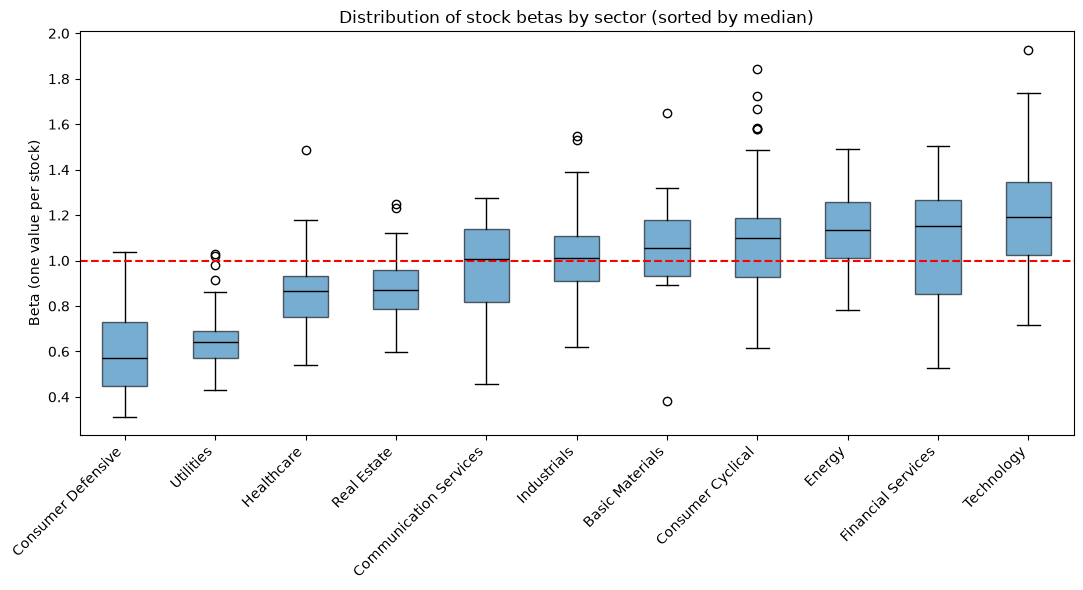

In [25]:
order = eligible.groupby("sector")["beta"].median().sort_values().index
data = [eligible.loc[eligible["sector"] == s, "beta"] for s in order]
#instead of using .loc i could've just done eligible[eligible["sector"] == s]["beta"]

fig, ax = plt.subplots(figsize=(11, 6))
ax.boxplot(data, patch_artist=True, boxprops=dict(alpha=0.6),
           medianprops=dict(color="black"))
ax.set_xticklabels(order, rotation=45, ha="right")
ax.axhline(1, color="red", linestyle="--")
ax.set_ylabel("Beta (one value per stock)")
ax.set_title("Distribution of stock betas by sector (sorted by median)")
plt.tight_layout()
plt.show()

- Defensive sectors tend to have lower betas, while cyclical and technology-oriented sectors tend to have higher betas.
- Consumer Defensive and Utilities stand out as having the lowest market sensitivity.
- Technology has the highest median beta in the dataset, suggesting that the typical Technology stock is more responsive to market movements than stocks in other sectors.
- Very important: Beta describes an estimated average sensitivity, not a guaranteed outcome.
- Some sectors contain substantial individual stock differences, seen by the wider IQR (wider distributions).
- Several sectors contain noteworthy outliers.
- Chart suggests that combining stocks from different sectors could help you build portfolios with different levels of market exposure. Combining Technology with Utilities could reduce a portfolio's overall market beta compared with holding only high-beta Technology stocks, depending on the portfolio weights and the individual stock betas.

#### 7.3 Do sectors really differ?

Two separate questions with the same method. In both, the unit of analysis is one stock, not a sector time series.  

- Q1: Do average stock betas differ between sectors?
- Q2: Do average stock returns differ between sectors?

H0: all sectors have equal mean beta (Q1) / mean annualized stock return (Q2).  
H1: at least one sector's mean beta/annualized stock return is different.

The goal is to compare means (numerical dependent variable) across more than two groups (categorical independent variable) without assuming that the groups have equal variance (boxplot suggests that Betas have different spread across sectors). For this reason, the test used will be Anova, more particularly, Welch's Anova (unequal variance).

Unlike phase's 6 tests, the sector groups are much smaller (20-80 stocks per sector instead of 200+ days in phase 6), so the CLT strength is weaker. The p-values should then be read as approximations, rather than certainties.

Q1 - Do mean betas differ between sectors?

In [26]:
#Just like done in section 6, will create the anova's functions that will be run:
from statsmodels.stats.oneway import anova_oneway

def welch_anova(df, group_col, value_col):
    groups=[g[value_col].dropna().values for _, g in df.groupby(group_col)]
    return anova_oneway(groups, use_var="unequal", welch_correction=True)

res_beta=welch_anova(eligible,"sector","beta")

res_beta

""" 

statistic = 41.677252559384414
#How strong is the observed difference relative to within-sector variability

pvalue = 3.1332695805257446e-38
df = (10.0, 148.81435684232184)

df_num = 10.0
#How many groups are being compared

df_denom = 148.81435684232184
#How is the uncertainty in the comparison reflected in the reference distribution

nobs_t = 498.0
n_groups = 11
means = array([1.05812781, 0.95507596, 1.1035896 , 0.5952111 , 1.14252068,
           1.08126241, 0.85973844, 1.01848744, 0.88471332, 1.21069871,
           0.66741569])
nobs = array([22., 22., 54., 37., 22., 67., 61., 69., 31., 82., 31.])
vars_ = array([0.05288894, 0.04371571, 0.07641179, 0.03250204, 0.0349671 ,
           0.05569254, 0.0279621 , 0.03993185, 0.02296869, 0.06156741,
           0.02367997])

Considering that p-value < 0.001, there is strong statistical evidence that average stock beta 
differs across sectors. This suggests that stocks in different sectors have different 
average sensitivities to market movements. Q1’s sector means run from 0.60 (Consumer Defensive) to 1.21 (Technology).
Nothing can be said which sectors have higher or lower betas, nor does it show that every pair of sectors differs significantly.
"""


' \n\nstatistic = 41.677252559384414\n#How strong is the observed difference relative to within-sector variability\n\npvalue = 3.1332695805257446e-38\ndf = (10.0, 148.81435684232184)\n\ndf_num = 10.0\n#How many groups are being compared\n\ndf_denom = 148.81435684232184\n#How is the uncertainty in the comparison reflected in the reference distribution\n\nnobs_t = 498.0\nn_groups = 11\nmeans = array([1.05812781, 0.95507596, 1.1035896 , 0.5952111 , 1.14252068,\n           1.08126241, 0.85973844, 1.01848744, 0.88471332, 1.21069871,\n           0.66741569])\nnobs = array([22., 22., 54., 37., 22., 67., 61., 69., 31., 82., 31.])\nvars_ = array([0.05288894, 0.04371571, 0.07641179, 0.03250204, 0.0349671 ,\n           0.05569254, 0.0279621 , 0.03993185, 0.02296869, 0.06156741,\n           0.02367997])\n\nConsidering that p-value < 0.001, there is strong statistical evidence that average stock beta \ndiffers across sectors. This suggests that stocks in different sectors have different \naverage s

Q2 - Do mean stock returns differ between sectors?

For this question, each stock's arithmetic mean daily return is annualised by multiplying it by 252. Returns and betas are estimated over the same observation window to ensure comparability.

In [ ]:
#I have the merged df which has the daily stock_return, market_return and sector for each symbol:
#So let's groupby symbol and annualize the return:

annualized_return=(merged.groupby("symbol")["stock_return"].mean()*252).rename("annualized_mean_return")
#with .rename() we are just naming the values column of the resulting series of symbol - annualized return

#symbols with at least 252 observations

eligible=eligible.merge(annualized_return, how="inner", on="symbol")

res_ret=welch_anova(eligible, "sector", "annualized_mean_return")

res_ret

""" 
statistic = 11.846594579154553
pvalue = 7.563084573887331e-15
df = (10.0, 147.9479683291403)
df_num = 10.0
df_denom = 147.9479683291403
nobs_t = 498.0
n_groups = 11
means = array([0.13406292, 0.14468938, 0.17197061, 0.08884412, 0.14643672,
           0.16060441, 0.14153467, 0.17894186, 0.10843937, 0.23965931,
           0.13358675])
nobs = array([22., 22., 54., 37., 22., 67., 61., 69., 31., 82., 31.])
vars_ = array([0.00394081, 0.01059451, 0.00739359, 0.00294569, 0.00886038,
           0.0028067 , 0.00757204, 0.00677096, 0.00220698, 0.01793726,
           0.01389775])
use_var = 'unequal'
welch_correction = True
tuple = (11.846594579154553, 7.563084573887331e-15)

Considering that p-value < 0.001, there is strong statistical evidence that average annualized stock returns differ across 
sectors. Q2’s run from 8.9% to 24.0% a year.
"""

" \nstatistic = 11.846594579154553\npvalue = 7.563084573887331e-15\ndf = (10.0, 147.9479683291403)\ndf_num = 10.0\ndf_denom = 147.9479683291403\nnobs_t = 498.0\nn_groups = 11\nmeans = array([0.13406292, 0.14468938, 0.17197061, 0.08884412, 0.14643672,\n           0.16060441, 0.14153467, 0.17894186, 0.10843937, 0.23965931,\n           0.13358675])\nnobs = array([22., 22., 54., 37., 22., 67., 61., 69., 31., 82., 31.])\nvars_ = array([0.00394081, 0.01059451, 0.00739359, 0.00294569, 0.00886038,\n           0.0028067 , 0.00757204, 0.00677096, 0.00220698, 0.01793726,\n           0.01389775])\nuse_var = 'unequal'\nwelch_correction = True\ntuple = (11.846594579154553, 7.563084573887331e-15)\n\nConsidering that p-value < 0.001, there is strong statistical evidence that average annualized stock returns differ across \nsectors. Q2’s run from 8.9% to 24.0% a year.\n"

Welch's ANOVA reveals statistically significant differences in both mean stock betas and mean annualised stock returns across the 11 sectors. These findings suggest that sector membership is associated with differences in average market risk exposure and realised returns in the sample. However, these do not identify which specific sectors differ. Also, the results should be interpreted with caution because cross-stock dependence may affect the reliability of conventional p-values.

#### 7.4 Sanity checks:

In [28]:
print("number of days:",len(market_ret))
print("number of stocks:",capm["symbol"].nunique())
print("any missing betas, alphas or r_squared?:", capm[["beta","alpha_daily","r_squared"]].isnull().any().any())
#just one any() would give me the result for each column (false, false, false). 
#the second any() just gives me the combined answer.
print("are r_squared between 0 and 1?:",capm["r_squared"].between(-1e-9, 1 + 1e-9).all())
print("no stock has more observations than the number of days of the period?",(capm["n_obs"] <= len(market_ret)).all())
print("at least one stock covers every index day?:",(capm["n_obs"].max())==len(market_ret))
print("sector summary covers all eligible stocks?:", sector_capm["n_stocks"].sum()==len(eligible))
print("are my self correlations all 1?",(pearson_sector_corr.values.diagonal()==1).all())
#or np.allclose(np.diag(corr.values), 1). this is better because np.allclose allows tiny
# differences like 1.000000001, etc.
print("all my correlations are between -1 and 1?:",((pearson_sector_corr>=-1)&(pearson_sector_corr<=1)).all().all()) #again, just one all() would give true or false for each column
#or ((corr.values >= -1) & (corr.values <= 1)).all()
#or np.all((corr.values >= -1) & (corr.values <= 1))
print("is my correlation matrix symmetric?:",pearson_sector_corr.equals(pearson_sector_corr.T))
#check if my correlation matrix is equal to the transposed version of it self (swap positions)



number of days: 2516
number of stocks: 502
any missing betas, alphas or r_squared?: False
are r_squared between 0 and 1?: True
no stock has more observations than the number of days of the period? True
at least one stock covers every index day?: True
sector summary covers all eligible stocks?: True
are my self correlations all 1? True
all my correlations are between -1 and 1?: True
is my correlation matrix symmetric?: True


### Saving results:

In [ ]:
destination = Path(r"filepath\csv_stats")

sector_corr_simpletable=pearson_sector_corr.stack().rename_axis(
    index=["sector_a", "sector_b"]
).reset_index(name="pearson_corr")
#stack() coverts columns into rows
#after stack() i get a two index level (sector a, sector b):
#sector           sector                
#Basic Materials  Basic Materials           1.000000
#                 Communication Services    0.764233
#rename_axis() renames the two indexes.
#reset_index() frees the two indexes (sectors) into each columns and names the values

sector_corr_simpletable["n_obs"]=len(sector_daily_pivot)
#sector_daily_pivot has the sector_return for each sector and each day
sector_corr_simpletable=sector_corr_simpletable[["sector_a", "sector_b", "n_obs", "pearson_corr"]]

sector_corr_simpletable.to_csv(destination / "sector_correlation.csv", index=False)
capm.to_csv(destination / "stock_capm.csv", index=False)
sector_capm.to_csv(destination / "sector_capm_stats.csv", index=False)